In [9]:
%reload_ext autoreload
%autoreload 2

In [67]:
#Imports
import nflreadpy as nfldat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import math
from sklearn import linear_model as lm

In [56]:
#Load stats for all players
player_stats = nfldat.load_player_stats(None, "reg")
pdplayerstats = player_stats.to_pandas()
#Get and print for one player
nabersstats = pdplayerstats[pdplayerstats["player_display_name"] == "Malik Nabers"]
print(nabersstats)

      player_id player_name player_display_name position position_group  \
894  00-0039337    M.Nabers        Malik Nabers       WR             WR   

                                          headshot_url  season season_type  \
894  https://static.www.nfl.com/image/upload/f_auto...    2026         REG   

    recent_team  games  ...  pt_out_of_bounds  pt_downed  pt_touchback  \
894         NYG      3  ...                 0          0             0   

     pt_fair_caught  pt_returned  pt_return_yards  pt_return_tds  \
894               0            0                0              0   

     pt_net_yards  fantasy_points  fantasy_points_ppr  
894             0             9.6                21.6  

[1 rows x 148 columns]


In [57]:
#Load Weekly Stats
weekly_player_stats_2025 = nfldat.load_player_stats(["2025"], "week")
pdwps2025 = weekly_player_stats_2025.to_pandas()
#Get for a single player
wpsJT = pdwps2025[pdwps2025["player_display_name"] == "Jonathan Taylor"]
wpsJT = wpsJT[wpsJT["season_type"] == "REG"]
print(wpsJT)

        player_id player_name player_display_name position position_group  \
365    00-0036223    J.Taylor     Jonathan Taylor       RB             RB   
1444   00-0036223    J.Taylor     Jonathan Taylor       RB             RB   
2542   00-0036223    J.Taylor     Jonathan Taylor       RB             RB   
3647   00-0036223    J.Taylor     Jonathan Taylor       RB             RB   
4704   00-0036223    J.Taylor     Jonathan Taylor       RB             RB   
5684   00-0036223    J.Taylor     Jonathan Taylor       RB             RB   
6694   00-0036223    J.Taylor     Jonathan Taylor       RB             RB   
7686   00-0036223    J.Taylor     Jonathan Taylor       RB             RB   
8593   00-0036223    J.Taylor     Jonathan Taylor       RB             RB   
9566   00-0036223    J.Taylor     Jonathan Taylor       RB             RB   
11547  00-0036223    J.Taylor     Jonathan Taylor       RB             RB   
12561  00-0036223    J.Taylor     Jonathan Taylor       RB             RB   

In [58]:
#Get only weekly PPR fantasy points and truncate to make it readable
JTpprpoints = wpsJT["fantasy_points_ppr"].tolist()
for i in range (len(JTpprpoints)):
    x = JTpprpoints[i]*100
    x = math.trunc(x)
    JTpprpoints[i] = x/100
print(JTpprpoints)

[12.8, 29.5, 32.79, 14.6, 31.6, 23.7, 34.2, 37.4, 7.7, 49.6, 8.6, 15.1, 11.4, 13.1, 16.89, 17.39, 5.9]


In [59]:
#Get Jonathan Taylor's weekly rushing attempts for 2025 season
#Same Season we got his fantasy points for
nextgenstats = nfldat.load_nextgen_stats(2025, "rushing")
pdngs = nextgenstats.to_pandas()
JTngs = pdngs[pdngs["player_display_name"] == "Jonathan Taylor"]
JTngs = JTngs[JTngs["season_type"] == "REG"]
JTngsRA = JTngs["rush_attempts"].tolist()
JTngsRAbyweek = JTngsRA[1:]
print(JTngsRAbyweek)

[18, 25, 17, 17, 17, 21, 16, 12, 14, 32, 16, 21, 21, 25, 16, 21, 14]


Text(0, 0.5, 'Rush Attempts')

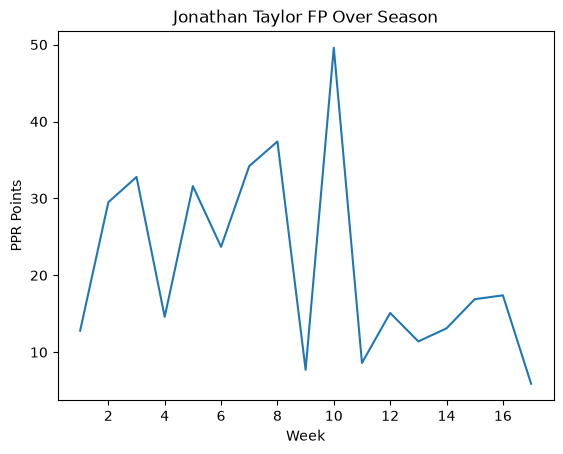

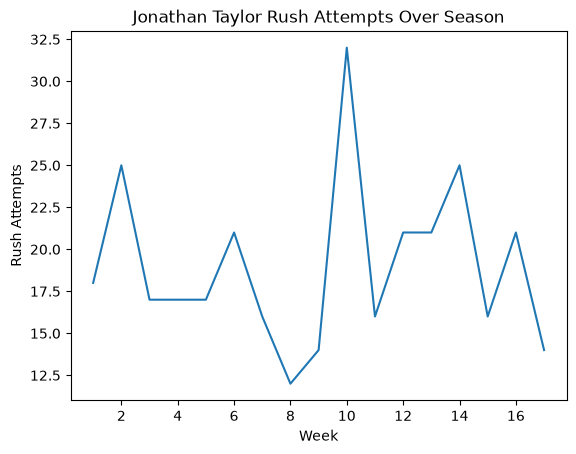

In [60]:
#Plot fantasy points over the season
plt.figure(1)
plt.plot(range(1, len(JTpprpoints)+1), JTpprpoints)
plt.title("Jonathan Taylor FP Over Season")
plt.xlabel("Week")
plt.ylabel("PPR Points")
#Plot rushing attempts over the season
plt.figure(2)
plt.plot(range(1, len(JTngsRAbyweek)+1), JTngsRAbyweek)
plt.title("Jonathan Taylor Rush Attempts Over Season")
plt.xlabel("Week")
plt.ylabel("Rush Attempts")

Text(0.5, 1.0, 'Jonathan Taylor Fantasy Points by Rushing Attempts 2025 Season')

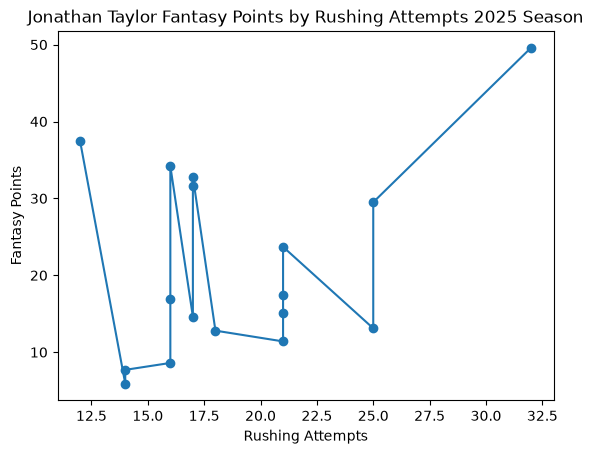

In [61]:
#plot Fantasy Points by Rushing Attempts

#Merge into tuples for sorting
merge = list(zip(JTngsRAbyweek, JTpprpoints))
merge = sorted(merge)
#After sorting, move back to lists
ra, fp = zip(*merge)
#Plot
plt.plot(ra, fp, marker = 'o')
plt.xlabel("Rushing Attempts")
plt.ylabel("Fantasy Points")
plt.title("Jonathan Taylor Fantasy Points by Rushing Attempts 2025 Season")

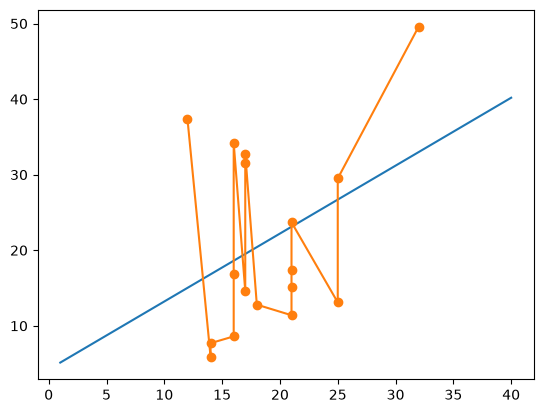

In [62]:
#Simple Linear Regression for the Data
#Using scikit learn
#Get regression model
reg = lm.LinearRegression()
#Take x-values into an array and reshape it to be a list of features
raarray = np.array(ra)
rashaped = np.reshape(raarray, (-1,1))
#take y-values to an array
fparray = np.array(fp)
#Fit the line
reg.fit(rashaped, fparray)
#take coef and intercept
m = float(reg.coef_[0])
b = float(reg.intercept_)
#Make points to plot
xvar = np.linspace(1,40,1000)
yvar = m * xvar + b
#Plot
plt.plot(xvar, yvar)
plt.plot(ra,fp,marker = "o")
plt.show()

[71, 165, 102, 76, 66, 123, 94, 153, 45, 244, 58, 85, 74, 87, 46, 70, 26]
[0, 0, 3, 0, 3, 1, 3, 2, 0, 3, 0, 0, 1, 0, 1, 1, 0]


Text(0, 0.5, 'Rush Yards')

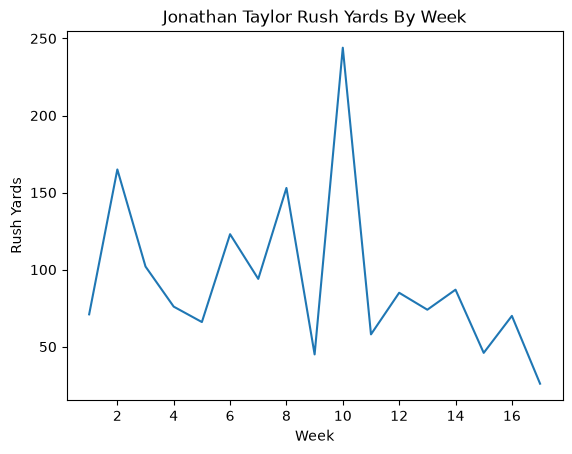

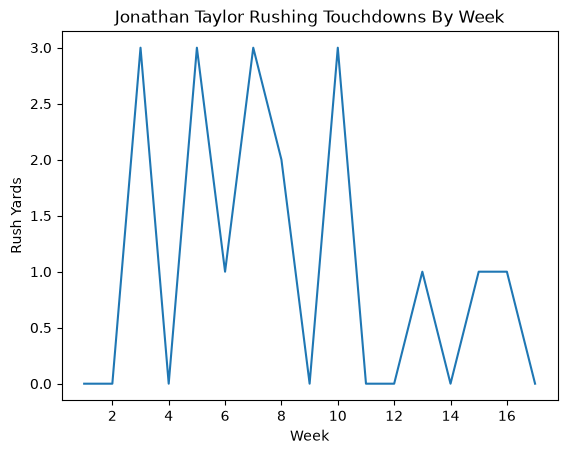

In [63]:
#This only considers one feature - Rushing Attempts. Lets try the same thing with more features
#Pull more stats - Rush yards, Rush touchdowns

#Rush Yards
JTngsRY = JTngs["rush_yards"].to_list()
JTngsRYbyweek = JTngsRY[1:]
print(JTngsRYbyweek)

#Rush Touchdowns
JTngsRT = JTngs["rush_touchdowns"].to_list()
JTngsRTbyweek = JTngsRT[1:]
print(JTngsRTbyweek)

#Plot Each
plt.figure(1)
plt.plot(range(1, len(JTngsRYbyweek)+1),JTngsRYbyweek)
plt.title("Jonathan Taylor Rush Yards By Week")
plt.xlabel("Week")
plt.ylabel("Rush Yards")

plt.figure(2)
plt.plot(range(1, len(JTngsRTbyweek)+1), JTngsRTbyweek)
plt.title("Jonathan Taylor Rushing Touchdowns By Week")
plt.xlabel("Week")
plt.ylabel("Rush Yards")

Text(0, 0.5, 'Weekly Fantasy Points')

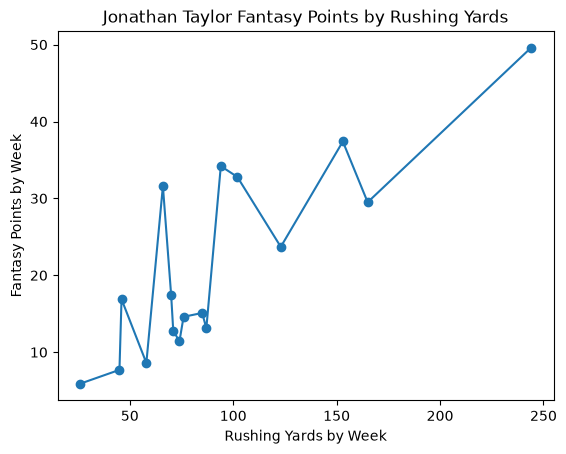

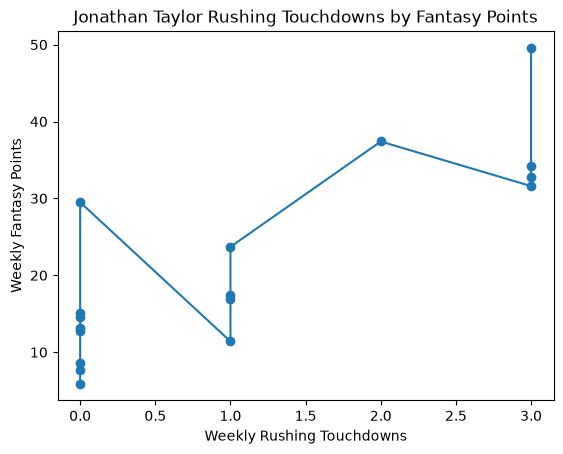

In [64]:
#Plot Fantasy Points by each of the new features:

mergeRYFP = list(zip(JTngsRYbyweek, JTpprpoints))
mergeRYFP = sorted(mergeRYFP)
ry, fp = zip(*mergeRYFP)
plt.figure(1)
plt.plot(ry, fp, marker = "o")
plt.title("Jonathan Taylor Fantasy Points by Rushing Yards")
plt.xlabel("Rushing Yards by Week")
plt.ylabel("Fantasy Points by Week")

mergeRTFP = list(zip(JTngsRTbyweek, JTpprpoints))
mergeRTFP = sorted(mergeRTFP)
rt, fp2 = zip(*mergeRTFP)
plt.figure(2)
plt.plot(rt, fp2, marker = "o")
plt.title("Jonathan Taylor Rushing Touchdowns by Fantasy Points")
plt.xlabel("Weekly Rushing Touchdowns")
plt.ylabel("Weekly Fantasy Points")

In [65]:
#Make a regression with 3 Features
#We already got the model earlier and saved it to reg

#Make features array
mergeFeatures = list(zip(ra, ry, rt))
features = np.array(mergeFeatures)
#We have fantasy points array from before

#fit the model
reg.fit(features, fparray)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[-5.08, 0.64,-3.29]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,61.67
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[213.74, 4.06, 2.43]"


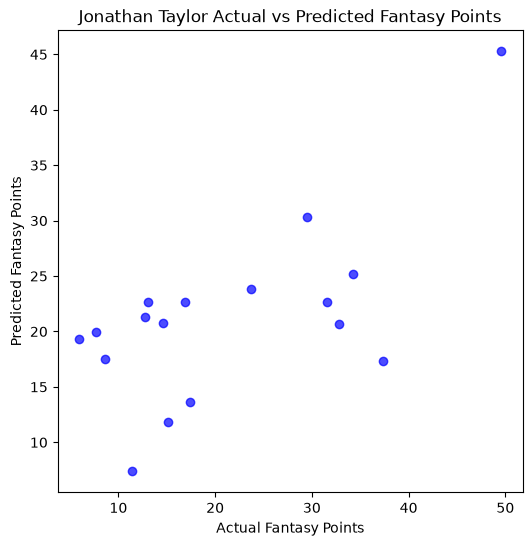

Text(0.5, 1.0, 'Residual Plot')

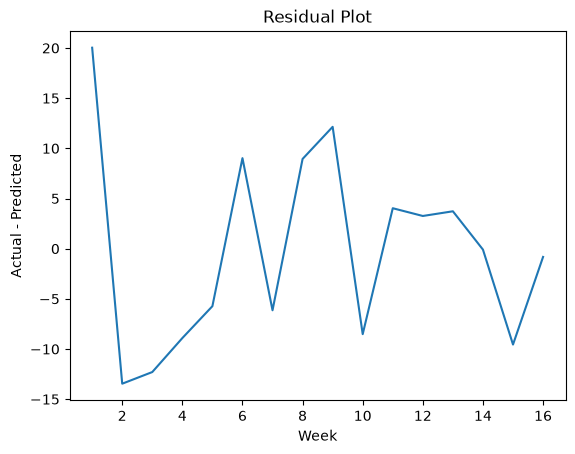

In [77]:
#Plot actual versus Predicted
fp_pred = reg.predict(features)
plt.figure(1, figsize = (6,6))
plt.scatter(fparray, fp_pred, color = "blue", alpha = 0.7)
plt.xlabel("Actual Fantasy Points")
plt.ylabel("Predicted Fantasy Points")
plt.title("Jonathan Taylor Actual vs Predicted Fantasy Points")
plt.show()

plt.figure(2)
diff = []
for i in range(0, len(fparray)-1):
    diff.append(float(fparray[i] - fp_pred[i]))
plt.plot(range(1, len(diff)+1), diff)
plt.xlabel("Week")
plt.ylabel("Actual - Predicted")
plt.title("Residual Plot")


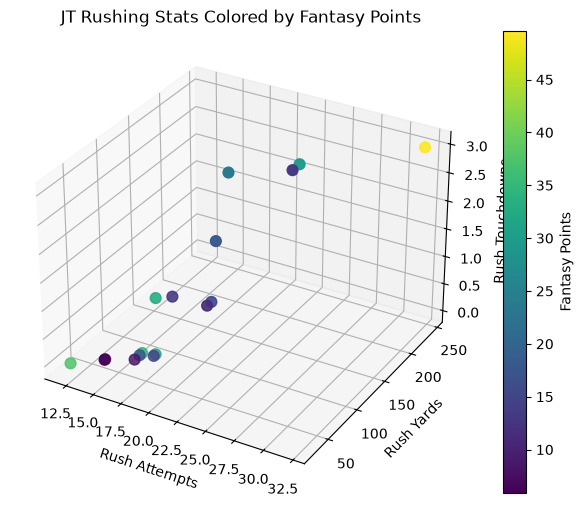

In [69]:
#3D Scatter
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection = "3d")

#X:RA; Y:RY; Z:RT; Color:FP
scatter = ax.scatter(features[:, 0], features[:, 1], features[:, 2], c=fparray, cmap="viridis", s=60)

ax.set_xlabel("Rush Attempts")
ax.set_ylabel("Rush Yards")
ax.set_zlabel("Rush Touchdowns")
plt.colorbar(scatter, label = "Fantasy Points")
plt.title("JT Rushing Stats Colored by Fantasy Points")
plt.show()

In [ ]:
#These Regressions work retrospectively when we know rush yards, fantasy points, etc
#Can we make it predictive?

In [16]:
#Checking our package for data loading
from pointsprojection import data
data.download("schedules", [2017])

yes
